# Generating class imbalance

**Imbalance** is a *row-changing* deficit: instead of (or in addition
to) changing values, the generator **removes or duplicates rows** — so
`Xt` is *smaller* than `X` (undersampling) or a *superset* of `X`
(oversampling; no row is ever dropped). Real datasets are rarely
balanced: rare events, censored observations, or biased sampling
processes skew the row distribution. This makes pipelines that assume
balanced classes or uniform feature coverage fail in instructive ways.

This notebook shows the **two levers** available in badgers:

1. **`UndersamplingGenerator`** — *removes* the rows flagged by a deficit
   **selector** (`ClassSelector` for exact per-class drops,
   `ProportionalSelector` for score-driven stochastic removal).
2. **`OversamplingGenerator`** — *duplicates* rows according to a per-row
   **multiplicity** selector (`ConstantMultiplicity` for uniform copies,
   `MaskedMultiplicity` for copies of selected rows only).

Both generators act on the observation process only — they **do not use
a DGP**: rows are removed or copied as-is, so any relationships between
columns are preserved on the surviving/duplicated rows.


## Goal

Remove rows so that some classes (or score regions) become under-represented, or duplicate rows so that some classes become over-represented — imbalance applied with selectors.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from numpy.random import default_rng
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.imbalance import (
    UndersamplingGenerator, OversamplingGenerator,
    ConstantMultiplicity, MaskedMultiplicity,
)
from badgers.core.selectors import ClassSelector, ProportionalSelector

rng = default_rng(seed=0)


In [2]:
X, y = make_blobs(centers=4, random_state=0)
# classes as a column of X
X = np.column_stack([X, y])  # NOTE: overwrites X with the 3-column version (blobs + class column)
column_mapping = {f"f{i}": i for i in range(X.shape[1])}
column_mapping["cls"] = X.shape[1] - 1
cls = X[:, column_mapping["cls"]].astype(int)   # explicit class vector for plotting
print(X.shape)

(100, 3)


## Part A — Undersampling (removing rows)

### Sample data from different classes

**What the selector does here:** `ClassSelector([0, 1],
class_column=2, ...)` reads the class labels from position 2 and builds
one boolean mask per class value from the given shares. The shares are
*fractions of the total row count*, clipped to the rows available in
each class; classes absent from `proportions` are kept as-is.
`UndersamplingGenerator` then removes exactly the affected rows.


In [ ]:
# WHO loses rows and how many: per-class share of the total row count
selector = ClassSelector([0, 1], class_column=2,
                         proportions={0:0.1, 1:0.05, 2:0.15, 3:0.2}, rng=rng)
gen = UndersamplingGenerator(random_generator=rng)
Xt = gen.generate(X=X.copy(), selector=selector)
print('row-removing:', X.shape, '->', Xt.shape)


In [4]:
# verify: per-class counts before and after
before = np.unique(X[:, column_mapping['cls']], return_counts=True)
after = np.unique(Xt[:, column_mapping['cls']], return_counts=True)
print('before:', dict(zip(before[0].astype(int), before[1].tolist())))
print('after :', dict(zip(after[0].astype(int), after[1].tolist())))
assert Xt.shape[0] < X.shape[0]


before: {np.int64(0): 25, np.int64(1): 25, np.int64(2): 25, np.int64(3): 25}
after : {np.int64(0): 15, np.int64(1): 20, np.int64(2): 10, np.int64(3): 5}


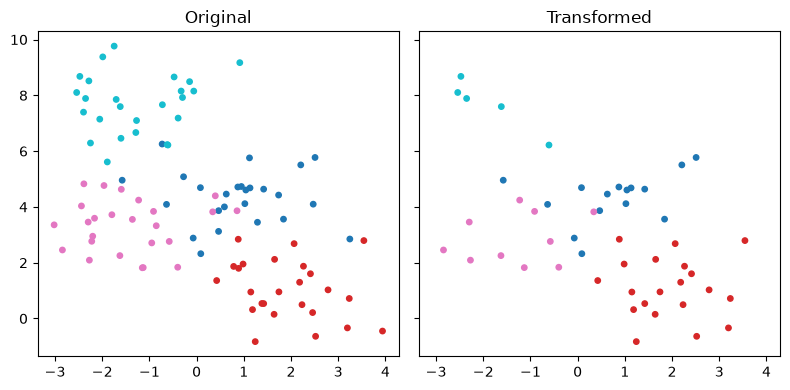

In [5]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], c=Xt[:, column_mapping['cls']].astype(int), cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed')
plt.tight_layout()

### Sample data proportionally to a column (stochastic removal)

**What the selector does here:** `ProportionalSelector([0, 1],
column=0)` reads column 0 (`f0`) and returns per-row **float scores in
[0, 1]** — the deficit probability grows with the value of `f0`. The
consumer, `UndersamplingGenerator`, removes each row **stochastically**
with probability equal to its deficit score: rows with a HIGH deficit
probability are dropped often, rows with a LOW one are kept most of the
time. The result concentrates on small-`f0` rows — a form of imbalance
driven by a continuous column.

For illustration we also compute a demo ranking variable `score` and
use it as a color: it is **not** a target and plays no role in the
selection.


In [ ]:
# demo ranking variable for coloring only
score = -2 * X[:, 0] + 3 * X[:, 1] + 5

# WHO loses rows: deficit probability proportional to f0 (stochastic removal)
selector = ProportionalSelector([0, 1], column=0)
gen = UndersamplingGenerator(random_generator=rng)
Xt = gen.generate(X=X.copy(), selector=selector)
print('row-removing:', X.shape, '->', Xt.shape)


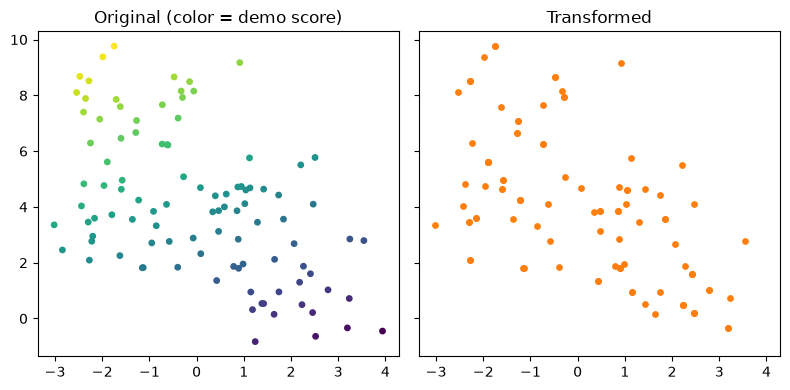

In [7]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
axes[0].scatter(X[:, 0], X[:, 1], c=score, cmap='viridis', s=15)
axes[1].scatter(Xt[:, 0], Xt[:, 1], color='C1', s=15)
axes[0].set_title('Original (color = demo score)')
axes[1].set_title('Transformed')
plt.tight_layout()

## Part B — Oversampling (duplicating rows)

The mirror image of undersampling: instead of dropping rows, the
`OversamplingGenerator` **duplicates** them according to a per-row
integer multiplicity (`1` = keep the row as-is, `k > 1` = keep `k`
copies). Two invariants:

- the output is a **superset** of the input — no row is ever dropped,
  and the original row order is preserved;
- `get_imbalance_labels()` reports, for each *input* row, whether it was
  duplicated (`True` = multiplicity > 1).

Multiplicity selectors: `ConstantMultiplicity(k)` assigns every row `k`
copies; `MaskedMultiplicity(mask, k)` assigns `k` copies to the rows
where `mask` is `True` (a `(n,)` bool array or a callable on `X`) and
`1` to the rest. Multiplicities must be integers `>= 1` — fractional
values are rejected (they look like a deficit `Selector`; use
`UndersamplingGenerator` for that).


In [ ]:
# oversample: 3 copies of every row
selector = ConstantMultiplicity(3)
gen = OversamplingGenerator(random_generator=rng)
Xt_os = gen.generate(X.copy(), selector=selector)
print('row-duplicating:', X.shape, '->', Xt_os.shape)

# every row was duplicated; no row was dropped
labels = gen.get_imbalance_labels()
print('labels:', len(labels), '| duplicated rows:', int(labels.sum()))
assert Xt_os.shape[0] == 3 * X.shape[0]
assert labels.all()
# no row dropped, original order preserved: the output is the input
# with each row repeated in place
assert np.array_equal(Xt_os, np.repeat(X, 3, axis=0))


In [ ]:
# oversample only class-0 rows: 3 copies where the mask is True
mask = cls == 0
selector = MaskedMultiplicity(mask, 3)
gen = OversamplingGenerator(random_generator=rng)
Xt_os = gen.generate(X.copy(), selector=selector)
print('row-duplicating:', X.shape, '->', Xt_os.shape)

# only the masked rows are flagged; per-class counts tripled for class 0
labels = gen.get_imbalance_labels()
assert (labels == mask).all()
before = dict(zip(*np.unique(cls, return_counts=True)))
after = dict(zip(*np.unique(Xt_os[:, column_mapping['cls']].astype(int), return_counts=True)))
print('before:', before)
print('after :', after)
assert after[0] == 3 * before[0]
for c in before:
    if c != 0:
        assert after[c] == before[c]   # unmasked rows appear exactly once

fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=cls, cmap='tab10', s=15)
axes[1].scatter(Xt_os[:, 0], Xt_os[:, 1],
                c=Xt_os[:, column_mapping['cls']].astype(int), cmap='tab10', s=15)
axes[0].set_title('Original')
axes[1].set_title('Transformed (class 0 x3)')
plt.tight_layout()


## Summary

| Generator | Effect on shape | Selection parameter |
|---|---|---|
| `UndersamplingGenerator` | removes rows per deficit selector | deficit `Selector`: `ClassSelector` (per-class shares), `ProportionalSelector` (float scores), boolean masks |
| `OversamplingGenerator` | duplicates rows per per-row multiplicity | `ConstantMultiplicity(k)`, `MaskedMultiplicity(mask, k)`, or an `(n,)` int array of multiplicities (all `>= 1`) |

* Imbalance is a *row-changing* deficit: undersampling makes `Xt`
  smaller than `X`, oversampling makes it a superset (no row dropped,
  order preserved).
* The selector decides **who** is affected; the generator realizes the
  decision.
* Both generators are observation-process operations — no DGP is
  involved, so the surviving/duplicated rows stay structurally
  consistent by construction.


## Takeaways

- `UndersamplingGenerator` removes the rows flagged by a deficit selector; `OversamplingGenerator` duplicates rows per per-row multiplicity.
- Selectors quantify which rows are affected; intensities (rate, quantile, multiplicity, mask) are constructor arguments.
- Neither generator uses a DGP: rows are removed or copied as-is, so any relationships between columns are preserved on the output rows.
- `get_imbalance_labels()` aligns with the **input** rows: `True` = removed (undersampling) or duplicated (oversampling).
